# Lung cancer numerical machine learning workflow

This notebook contains the actual **preprocessing, machine-learning training and evaluation code** for the Akash Nath Kaggle dataset, version 2. It includes data auditing, a fixed split, training-only exploration, five-fold model selection, saving the fitted pipeline, held-out metrics, plots and feature-reliance diagnostics.

The Streamlit application stays separate and reads the existing saved model and reports. **Run All reuses the installed model by default.** Change `TRAIN_NEW_MODEL` only when you intend to train and activate a new run. Existing model folders and the original held-out evaluation are preserved.

This predicts source NO/YES dataset labels. The saved test performance is near chance and does not establish reliable clinical detection. Questionnaire codes are not assumed to be symptom severity levels.

In VS Code, select the project's `.venv` Python interpreter as the notebook kernel, then use **Run All**. Run from the project root or its `notebooks` folder.


In [1]:
from pathlib import Path
import os
import sys

project = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
                if (folder / 'lung_tabular').is_dir() and (folder / 'notebooks/train.ipynb').is_file()), None)
if project is None:
    raise RuntimeError('Open this notebook from the project root or its notebooks folder.')
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
print('Project:', project)
print('Python:', sys.version.split()[0])


Project: C:\Users\ASUS\Desktop\Aiml Project
Python: 3.12.10


In [2]:
import hashlib
import json
import math
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from lung_tabular import ARTIFACTS, DATA, FEATURES, LABELS, REPORTS, SCHEMA_VERSION, TARGET
from lung_tabular.data import download_data, encode_features, normalize_columns, read_prepared
from lung_tabular.model import load_model, predict_records, resolve_run
from lung_tabular.utils import read_json, sha256, write_json


In [3]:
from IPython.display import display
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_curve

TRAIN_NEW_MODEL = False
RUN_NAME = 'numerical_notebook_run'  # Use a new name for each training run.
REGENERATE_DIAGNOSTICS = False


## 1 Source data and provenance

The download helper verifies the existing CSV or downloads Kaggle version 2 if it is missing. The original file and its recorded SHA-256 identify the input source. The source contains AGE, GENDER, thirteen coded questionnaire fields and LUNG_CANCER. Clinical label provenance and patient identities are unverified.


In [4]:
source = download_data(DATA)
raw = normalize_columns(pd.read_csv(DATA / 'lung_cancer.csv'))
display(pd.Series({key: source.get(key) for key in ('source_page', 'version', 'license', 'csv_sha256')}, name='Source'))
display(raw.head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum()}))
print('Raw shape:', raw.shape)


source_page    https://www.kaggle.com/datasets/akashnath29/lu...
version                                                        2
license        Database: Open Database, Contents: © Original ...
csv_sha256     417052af60ea9da985478d93d6be49749d25c8d0168a14...
Name: Source, dtype: object

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,M,65,1,1,1,2,2,1,2,2,2,2,2,2,1,NO
1,F,55,1,2,2,1,1,2,2,2,1,1,1,2,2,NO
2,F,78,2,2,1,1,1,2,1,2,1,1,2,1,1,YES
3,M,60,2,1,1,1,2,1,2,1,1,2,1,2,2,YES
4,F,80,1,1,2,1,1,2,1,2,1,1,1,1,2,NO


,dtype,missing
GENDER,object,0
AGE,int64,0
SMOKING,int64,0
YELLOW_FINGERS,int64,0
ANXIETY,int64,0
PEER_PRESSURE,int64,0
CHRONIC_DISEASE,int64,0
FATIGUE,int64,0
ALLERGY,int64,0
WHEEZING,int64,0


Raw shape: (3000, 16)


## 2 Preprocessing and reproducible splitting

The implementation below normalises columns, validates explicit source codes, maps F/M to 0/1 and source binary codes 1/2 to 0/1, and maps NO/YES targets to 0/1. The shared `encode_features` validator also remains in the application because new prediction inputs require the same checks.

Identical feature profiles receive stable hashes. Conflicting-label groups are quarantined and duplicate profiles removed before a seed-42 stratified 80/20 split. Existing prepared records are hash-verified and reused. Test records never fit preprocessing or select a candidate. StandardScaler is fitted inside each training CV fold as part of the pipeline.


In [5]:
def prepare_data(data_dir=DATA, reports=REPORTS):
    data_dir, reports = Path(data_dir), Path(reports)
    csv = data_dir / "lung_cancer.csv"
    source = read_json(data_dir / "source.json")
    if sha256(csv) != source["csv_sha256"]:
        raise ValueError("Raw CSV no longer matches the recorded dataset hash.")
    if (reports / "dataset_summary.json").exists():
        _, summary = read_prepared(data_dir, reports)
        return summary
    raw = normalize_columns(pd.read_csv(csv))
    if TARGET not in raw:
        raise ValueError("Dataset is missing LUNG_CANCER.")
    target = raw[TARGET].astype(str).str.strip().str.upper()
    if not target.isin(["NO", "YES"]).all():
        raise ValueError("Targets must be YES or NO; unknown labels are not remapped.")
    encoded = encode_features(raw.drop(columns=TARGET), "survey")
    encoded[TARGET] = target.map({"NO": 0, "YES": 1})
    encoded["row_id"] = [hashlib.sha256(json.dumps([int(v) for v in values]).encode()).hexdigest()
                         for values in encoded.loc[:, list(FEATURES)].itertuples(index=False, name=None)]
    conflict_ids = set(encoded.groupby("row_id")[TARGET].nunique().loc[lambda values: values > 1].index)
    conflicting = encoded[encoded["row_id"].isin(conflict_ids)]
    remaining = encoded[~encoded["row_id"].isin(conflict_ids)]
    duplicates = remaining[remaining.duplicated("row_id", keep="first")]
    clean = remaining.drop_duplicates("row_id").sort_values("row_id").reset_index(drop=True)
    train_ids, test_ids = train_test_split(clean.row_id, test_size=0.20, stratify=clean[TARGET], random_state=42)
    clean["split"] = np.where(clean.row_id.isin(set(train_ids)), "train", "test")
    split_id = hashlib.sha256(json.dumps(clean.to_dict(orient="records"), sort_keys=True).encode()).hexdigest()
    summary = {"schema_version": SCHEMA_VERSION, "split_id": split_id, "csv_sha256": source["csv_sha256"],
               "source": source, "raw_rows": len(raw), "usable_rows": len(clean),
               "duplicate_rows_removed": len(duplicates), "conflicting_rows_removed": len(conflicting),
               "conflicting_feature_groups": len(conflict_ids), "features": list(FEATURES),
               "age_range": [int(encoded.AGE.min()), int(encoded.AGE.max())], "seed": 42,
               "split_counts": {split: {label: int(((clean.split == split) & (clean[TARGET] == value)).sum())
                                        for value, label in enumerate(("NO", "YES"))} for split in ("train", "test")},
               "limitation": "No verified patient IDs or external validation; source label provenance is unverified."}
    reports.mkdir(parents=True, exist_ok=True)
    clean.to_csv(reports / "prepared_records.csv", index=False)
    exclusions = pd.concat([conflicting.assign(reason="conflicting label for identical features"),
                            duplicates.assign(reason="duplicate feature record")])
    exclusions.loc[:, ["row_id", "reason"]].to_csv(reports / "exclusions.csv", index=False)
    write_json(reports / "dataset_summary.json", summary)
    return summary

In [6]:
summary = prepare_data(DATA, REPORTS)
records, summary = read_prepared(DATA, REPORTS)
training = records.loc[records['split'] == 'train'].copy()
testing = records.loc[records['split'] == 'test'].copy()
display(pd.Series({key: summary[key] for key in (
    'raw_rows', 'usable_rows', 'duplicate_rows_removed', 'conflicting_rows_removed',
    'conflicting_feature_groups', 'age_range', 'seed', 'split_id')}, name='Data audit'))
display(pd.DataFrame(summary['split_counts']).rename_axis('Dataset label'))
assert set(training['row_id']).isdisjoint(testing['row_id'])
print('Training records:', len(training), '| Reserved test records:', len(testing))


raw_rows                                                                   3000
usable_rows                                                                2994
duplicate_rows_removed                                                        2
conflicting_rows_removed                                                      4
conflicting_feature_groups                                                    2
age_range                                                              [30, 80]
seed                                                                         42
split_id                      84603db211dc1463ee020039f3227caad73f3a8cf4b274...
Name: Data audit, dtype: object

,train,test
Dataset label,,
NO,1183,296
YES,1212,303


Training records: 2395 | Reserved test records: 599


## 3 Training-only exploratory analysis

Explore only the training partition when deciding future changes. These charts describe source records, not a representative clinical population. The reserved test partition remains outside candidate selection.


,count,mean,std,min,25%,50%,75%,max
AGE,2395.0,55.141545,14.726368,30.0,43.0,55.0,68.0,80.0
GENDER,2395.0,0.509812,0.500008,0.0,0.0,1.0,1.0,1.0
SMOKING,2395.0,0.491441,0.500031,0.0,0.0,0.0,1.0,1.0
YELLOW_FINGERS,2395.0,0.510230,0.500000,0.0,0.0,1.0,1.0,1.0
ANXIETY,2395.0,0.490605,0.500016,0.0,0.0,0.0,1.0,1.0
PEER_PRESSURE,2395.0,0.501044,0.500103,0.0,0.0,1.0,1.0,1.0
CHRONIC_DISEASE,2395.0,0.511065,0.499982,0.0,0.0,1.0,1.0,1.0
FATIGUE,2395.0,0.493528,0.500063,0.0,0.0,0.0,1.0,1.0
ALLERGY,2395.0,0.510647,0.499991,0.0,0.0,1.0,1.0,1.0
WHEEZING,2395.0,0.500626,0.500104,0.0,0.0,1.0,1.0,1.0


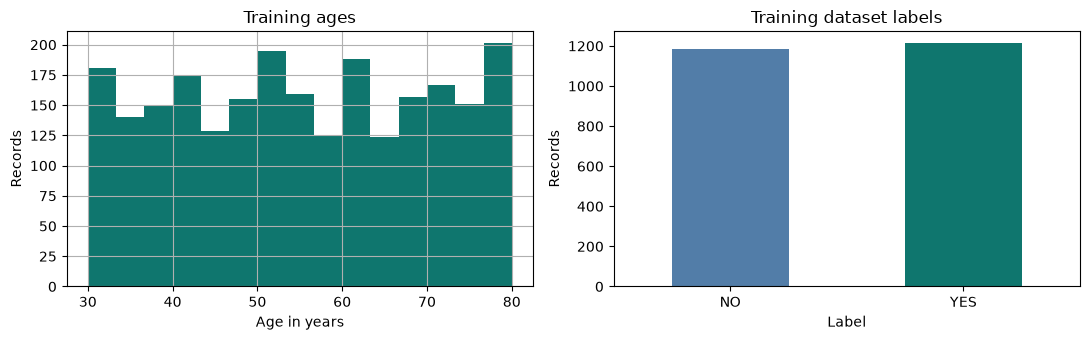

In [7]:
display(training.loc[:, list(FEATURES)].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
training['AGE'].hist(bins=15, ax=axes[0], color='#0F766E')
axes[0].set(title='Training ages', xlabel='Age in years', ylabel='Records')
training[TARGET].map({0: 'NO', 1: 'YES'}).value_counts().reindex(['NO', 'YES']).plot.bar(
    ax=axes[1], color=['#527DA8', '#0F766E'], rot=0)
axes[1].set(title='Training dataset labels', xlabel='Label', ylabel='Records')
fig.tight_layout()
plt.show()
plt.close(fig)


## 4 Machine learning candidates

Compare two regularised logistic regressions, two random forests and histogram gradient boosting. Candidate settings and the seed are defined here. Model selection uses mean training-only macro F1 over five stratified folds, with name as the tie-breaker. Balanced accuracy and ROC AUC are also recorded as CV measurements.


In [8]:
def candidates():
    return {
        "logistic_C0.1": LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000, random_state=42),
        "logistic_C1": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=42),
        "random_forest_depth6": RandomForestClassifier(n_estimators=160, max_depth=6, min_samples_leaf=5,
                                                       class_weight="balanced", n_jobs=1, random_state=42),
        "random_forest_full": RandomForestClassifier(n_estimators=160, min_samples_leaf=5,
                                                     class_weight="balanced", n_jobs=1, random_state=42),
        "hist_gradient_boosting": HistGradientBoostingClassifier(max_iter=120, max_leaf_nodes=7,
                                                                  learning_rate=0.05, l2_regularization=2,
                                                                  class_weight="balanced", random_state=42),
    }

## 5 Evaluation calculations

The following function calculates accuracy and its Wilson interval, balanced accuracy, macro F1, ROC AUC, confusion matrix and per-class precision/recall/F1. YES is class 1; the confusion matrix uses actual labels as rows and predicted labels as columns. The decision threshold is fixed at 0.5. Scores are not calibrated individual disease probabilities.


In [9]:
def metrics(truth, predicted, scores):
    accuracy = float(accuracy_score(truth, predicted))
    n, z = len(truth), 1.95996398454
    denominator = 1 + z*z/n
    centre = (accuracy + z*z/(2*n))/denominator
    radius = z*math.sqrt(accuracy*(1-accuracy)/n + z*z/(4*n*n))/denominator
    return {"records": n, "accuracy": accuracy,
            "accuracy_wilson_95": [centre-radius, centre+radius],
            "balanced_accuracy": float(balanced_accuracy_score(truth, predicted)),
            "macro_f1": float(f1_score(truth, predicted, average="macro", zero_division=0)),
            "roc_auc": float(roc_auc_score(truth, scores)),
            "confusion_matrix": confusion_matrix(truth, predicted, labels=[0, 1]).tolist(),
            "per_class": classification_report(truth, predicted, labels=[0, 1], target_names=list(LABELS),
                                                output_dict=True, zero_division=0)}

## 6 Cross validation and saving the selected model

This is the full training implementation. Each CV fold fits its own scaler; the winning pipeline is fitted on the complete training partition and saved with joblib. Reloaded predictions are checked. Metadata, candidate CV scores and the active model pointer use the same format as the Streamlit app.

The original held-out evaluation is written only if no frozen test report exists. Later runs report CV only and preserve that test report. Do not use the previously viewed test results to tune candidates or claim an independent evaluation. Reusing a run name raises an error instead of overwriting it.


In [10]:
def train_run(run_name="numerical_v1", data_dir=DATA, reports=REPORTS, artifacts=ARTIFACTS, candidate_factory=None):
    if Path(run_name).name != run_name or run_name in {".", "..", ""}:
        raise ValueError("Run name must be a single directory name.")
    artifacts, reports = Path(artifacts), Path(reports)
    run = artifacts / run_name
    if run.exists():
        raise ValueError("This run already exists. Use a new --run-name; existing model and results are preserved.")
    prepare_data(data_dir, reports)
    frame, summary = read_prepared(data_dir, reports)
    training = frame.loc[frame.split == "train"]
    x, y = training.loc[:, list(FEATURES)], training[TARGET]
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scoring = {"macro_f1": "f1_macro", "balanced_accuracy": "balanced_accuracy", "roc_auc": "roc_auc"}
    comparison, fitted = [], {}
    started = time.perf_counter()
    for name, classifier in (candidate_factory or candidates)().items():
        # Each fold fits its own scaler; no test or validation preprocessing leakage.
        pipeline = Pipeline([("scale", StandardScaler()), ("classifier", classifier)])
        scores = cross_validate(pipeline, x, y, cv=folds, scoring=scoring, n_jobs=1, error_score="raise")
        row = {"model": name}
        for metric in scoring:
            row[f"cv_{metric}"] = float(scores[f"test_{metric}"].mean())
            row[f"cv_{metric}_std"] = float(scores[f"test_{metric}"].std())
        comparison.append(row)
        fitted[name] = pipeline
        print(f"{name}: CV macro F1={row['cv_macro_f1']:.4f}, ROC AUC={row['cv_roc_auc']:.4f}", flush=True)
    comparison.sort(key=lambda row: (-row["cv_macro_f1"], row["model"]))
    winner = comparison[0]["model"]
    model = fitted[winner].fit(x, y)
    run.mkdir(parents=True)
    joblib.dump(model, run / "model.joblib", compress=3)
    reloaded = joblib.load(run / "model.joblib")
    if not np.allclose(model.predict_proba(x.iloc[:5]), reloaded.predict_proba(x.iloc[:5])):
        raise ValueError("Saved-model reloading changed numerical predictions.")
    test_metrics = None
    if not (reports / "test_evaluation.json").exists():
        # The candidate is now frozen. Evaluate the reserved partition once.
        testing = frame.loc[frame.split == "test"]
        test_x, test_y = testing.loc[:, list(FEATURES)], testing[TARGET]
        probabilities = model.predict_proba(test_x)[:, 1]
        prediction = (probabilities >= 0.5).astype(int)
        test_metrics = metrics(test_y, prediction, probabilities)
        dummy = DummyClassifier(strategy="most_frequent").fit(x, y)
        baseline = metrics(test_y, dummy.predict(test_x), dummy.predict_proba(test_x)[:, 1])
        test_metrics.update({"model": winner, "run": run_name, "split_id": summary["split_id"],
                             "threshold": 0.5, "baseline": baseline, "evaluation": "single fixed held-out row-level test"})
        write_json(reports / "test_evaluation.json", test_metrics)
        prediction_table = testing.loc[:, ["row_id", TARGET]].copy()
        prediction_table["predicted_label"] = [LABELS[value] for value in prediction]
        prediction_table["yes_model_score"] = probabilities
        prediction_table.to_csv(run / "test_predictions.csv", index=False)
    metadata = {"schema_version": SCHEMA_VERSION, "model": winner, "run": run_name, "features": list(FEATURES),
                "labels": list(LABELS), "age_range": summary["age_range"], "split_id": summary["split_id"],
                "csv_sha256": summary["csv_sha256"], "model_sha256": sha256(run / "model.joblib"),
                "sklearn_version": sklearn.__version__, "training_records": len(training), "cv_folds": 5,
                "selection_metric": "five-fold training-only macro F1; name breaks ties", "comparison": comparison,
                "training_seconds": time.perf_counter()-started, "created_utc": datetime.now(timezone.utc).isoformat(),
                "device": "CPU", "test_metrics": test_metrics,
                "classifier_parameters": model.named_steps["classifier"].get_params(),
                "quality_note": "Exploratory numerical dataset-label classification; clinical performance is unverified.",
                "evaluation_note": "Held-out test evaluated after CV selection." if test_metrics else
                                   "CV only: this dataset's test split was previously viewed; no fresh independent test score."}
    if comparison[0]["cv_balanced_accuracy"] < 0.60 or (test_metrics and test_metrics["balanced_accuracy"] < 0.60):
        metadata["quality_note"] = "Performance is near chance. This dataset/model has not demonstrated reliable predictive skill."
    write_json(run / "metadata.json", metadata)
    pd.DataFrame(comparison).to_csv(run / "cv_comparison.csv", index=False)
    write_json(artifacts / "active.json", {"run": run_name, "model_sha256": metadata["model_sha256"],
                                           "split_id": metadata["split_id"], "schema_version": SCHEMA_VERSION})
    return metadata

In [11]:
if TRAIN_NEW_MODEL:
    metadata = train_run(RUN_NAME, DATA, REPORTS, ARTIFACTS)
    print('Trained and activated:', metadata['run'])
else:
    print('Training disabled: reusing the existing saved model without changing it.')
run, metadata = resolve_run(ARTIFACTS)
model, metadata = load_model(run)
print('Active model:', metadata['model'], '| Run:', metadata['run'])
print('Evaluation note:', metadata['evaluation_note'])


Training disabled: reusing the existing saved model without changing it.
Active model: hist_gradient_boosting | Run: numerical_v1
Evaluation note: Held-out test evaluated after CV selection.


## 7 Training cross validation results

The table and chart below belong to the active model run. These are CV scores on training records, not held-out test scores. The app reads the same saved metadata and CSV.


,cv_macro_f1,cv_macro_f1_std,cv_balanced_accuracy,cv_balanced_accuracy_std,cv_roc_auc,cv_roc_auc_std
model,,,,,,
hist_gradient_boosting,0.5236,0.0187,0.5242,0.0185,0.5309,0.0146
logistic_C0.1,0.5129,0.0100,0.5131,0.0100,0.5114,0.0158
logistic_C1,0.5125,0.0107,0.5127,0.0108,0.5115,0.0158
random_forest_full,0.5093,0.0030,0.5093,0.0030,0.5194,0.0110
random_forest_depth6,0.5089,0.0049,0.5090,0.0048,0.5215,0.0085


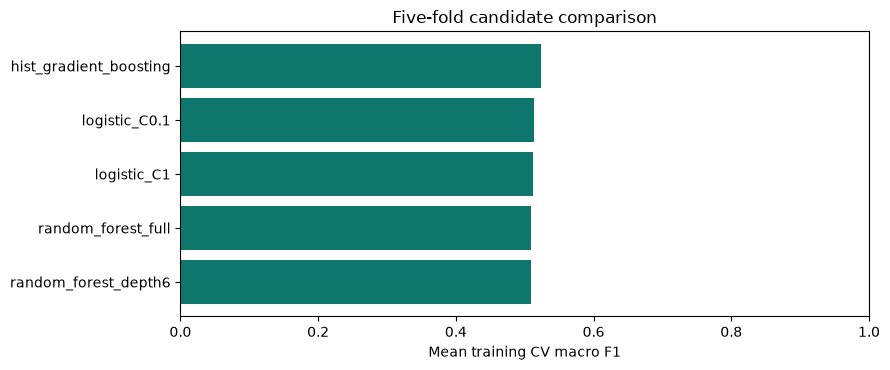

In [12]:
comparison = pd.DataFrame(metadata['comparison']).sort_values('cv_macro_f1', ascending=False)
display(comparison.set_index('model').round(4))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(comparison['model'], comparison['cv_macro_f1'], color='#0F766E')
ax.invert_yaxis()
ax.set(xlabel='Mean training CV macro F1', title='Five-fold candidate comparison', xlim=(0, 1))
fig.tight_layout()
plt.show()
plt.close(fig)


## 8 Frozen held out evaluation and baseline

Read the original evaluation without refitting a model or overwriting test metrics. The report identifies its own run; it must not be attached to a different, later CV-only model. Compare against a majority-label baseline. Near-chance performance does not support clinical detection claims.


In [13]:
evaluation = read_json(REPORTS / 'test_evaluation.json')
evaluated_run = ARTIFACTS / evaluation['run']
evaluated_metadata = read_json(evaluated_run / 'metadata.json')
if evaluation['split_id'] != summary['split_id']:
    raise ValueError('Saved evaluation belongs to a different prepared split.')
print('Frozen evaluated run:', evaluation['run'], '| Active run:', metadata['run'])
if evaluation['run'] != metadata['run']:
    print('The following test results belong ONLY to the frozen evaluated run, not the active CV-only run.')
rows = []
for label, result in ((evaluation['model'], evaluation), ('Majority-label baseline', evaluation['baseline'])):
    positive = result['per_class']['YES']
    rows.append({'Model': label, 'Accuracy': result['accuracy'], 'YES precision': positive['precision'],
                 'YES recall': positive['recall'], 'YES F1': positive['f1-score'],
                 'Macro F1': result['macro_f1'], 'Balanced accuracy': result['balanced_accuracy'],
                 'ROC AUC': result['roc_auc']})
display(pd.DataFrame(rows).set_index('Model').round(4))
print('95% Wilson accuracy interval:', evaluation['accuracy_wilson_95'])
display(pd.DataFrame(evaluation['per_class']).T)


Frozen evaluated run: numerical_v1 | Active run: numerical_v1


,Accuracy,YES precision,YES recall,YES F1,Macro F1,Balanced accuracy,ROC AUC
Model,,,,,,,
hist_gradient_boosting,0.5092,0.5170,0.4521,0.4824,0.5079,0.5099,0.5309
Majority-label baseline,0.5058,0.5058,1.0000,0.6718,0.3359,0.5000,0.5000


95% Wilson accuracy interval: [0.4692169486578002, 0.549029971554885]


,precision,recall,f1-score,support
NO,0.502994,0.567568,0.533333,296.000000
YES,0.516981,0.452145,0.482394,303.000000
accuracy,0.509182,0.509182,0.509182,0.509182
macro avg,0.509988,0.509856,0.507864,599.000000
weighted avg,0.510069,0.509182,0.507566,599.000000


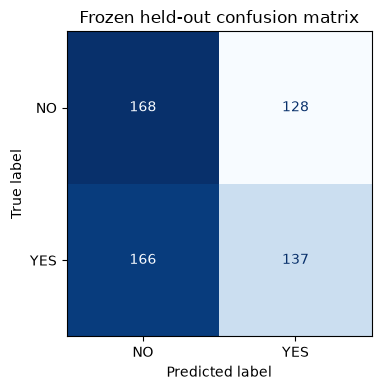

In [14]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(np.asarray(evaluation['confusion_matrix']), display_labels=list(LABELS)).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Frozen held-out confusion matrix')
fig.tight_layout()
plt.show()
plt.close(fig)


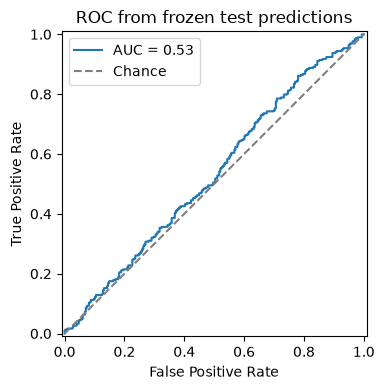

In [15]:
prediction_file = evaluated_run / 'test_predictions.csv'
if prediction_file.exists():
    frozen_predictions = pd.read_csv(prediction_file)
    reserved = testing.set_index('row_id')[TARGET]
    if (frozen_predictions['row_id'].duplicated().any()
            or set(frozen_predictions['row_id']) != set(reserved.index)
            or not np.array_equal(frozen_predictions[TARGET], reserved.loc[frozen_predictions['row_id']].to_numpy())):
        raise ValueError('Saved test predictions do not match the fixed held-out records.')
    fpr, tpr, _ = roc_curve(frozen_predictions[TARGET], frozen_predictions['yes_model_score'])
    fig, ax = plt.subplots(figsize=(5.5, 4))
    RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=evaluation['roc_auc']).plot(ax=ax)
    ax.plot([0, 1], [0, 1], '--', color='gray', label='Chance')
    ax.set_title('ROC from frozen test predictions')
    ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)
else:
    print('No saved test-prediction file; ROC is not recomputed using another model.')


## 9 Training only feature reliance

Permutation importance uses at most 512 training records, five shuffles and balanced accuracy. It measures in-sample model reliance, not independent validation, causality or clinical feature relevance. Regeneration is optional; the default reads existing evidence and leaves it unchanged.


In [16]:
def generate_diagnostics(data_dir=DATA, reports=REPORTS):
    run, _ = resolve_run()
    model, metadata = load_model(run)
    frame, summary = read_prepared(data_dir, reports)
    if summary["split_id"] != metadata["split_id"]:
        raise ValueError("Diagnostic records do not match the model's training split.")
    training = frame.loc[frame.split == "train"]
    sample = training.sample(n=min(512, len(training)), random_state=42)
    x, y = sample.loc[:, list(FEATURES)], sample[TARGET]
    result = permutation_importance(model, x, y, scoring="balanced_accuracy", n_repeats=5,
                                    random_state=42, n_jobs=1)
    payload = {"model_sha256": metadata["model_sha256"], "split_id": metadata["split_id"],
               "run": metadata["run"], "partition": "training only", "records": len(sample),
               "repeats": 5, "seed": 42, "scoring": "balanced accuracy",
               "training_subset_score": float(balanced_accuracy_score(y, model.predict(x))),
               "features": [{"feature": name, "importance": float(mean), "std": float(std)}
                            for name, mean, std in zip(FEATURES, result.importances_mean, result.importances_std)],
               "limitation": "In-sample reliance on training records, not external validation, clinical relevance, or causality."}
    write_json(Path(reports) / "feature_importance.json", payload)
    return {"run": metadata["run"], "partition": payload["partition"], "records": len(sample)}

Diagnostic run: numerical_v1 | Partition: training only


,feature,importance,std
13,SWALLOWING_DIFFICULTY,-0.003512,0.003762
6,CHRONIC_DISEASE,-0.001195,0.004361
1,GENDER,0.000754,0.003370
4,ANXIETY,0.003171,0.003186
3,YELLOW_FINGERS,0.005102,0.009732
10,ALCOHOL_CONSUMING,0.007601,0.010810
2,SMOKING,0.008963,0.006502
12,SHORTNESS_OF_BREATH,0.008990,0.003147
5,PEER_PRESSURE,0.010213,0.005184
8,ALLERGY,0.010222,0.005013


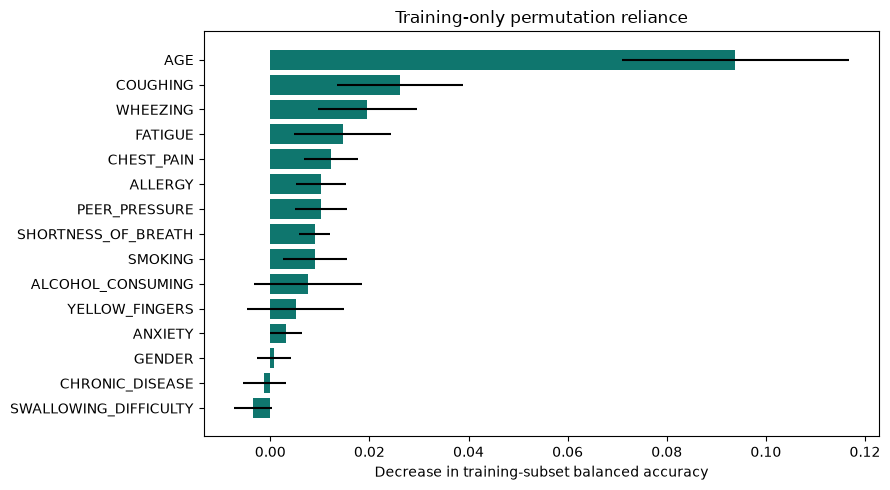

In [17]:
if REGENERATE_DIAGNOSTICS:
    display(generate_diagnostics(DATA, REPORTS))
diagnostics_file = REPORTS / 'feature_importance.json'
if diagnostics_file.exists():
    diagnostics = read_json(diagnostics_file)
    print('Diagnostic run:', diagnostics['run'], '| Partition:', diagnostics['partition'])
    if diagnostics['model_sha256'] != metadata['model_sha256']:
        print('These saved diagnostics belong to a different model; they are not attributed to the active run.')
    importance = pd.DataFrame(diagnostics['features']).sort_values('importance')
    display(importance)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(importance['feature'], importance['importance'], xerr=importance['std'], color='#0F766E')
    ax.set(xlabel='Decrease in training-subset balanced accuracy', title='Training-only permutation reliance')
    fig.tight_layout()
    plt.show()
    plt.close(fig)
else:
    print('No saved diagnostics. Enable REGENERATE_DIAGNOSTICS to calculate them on training records.')


## 10 Application integration check

The application still loads a hash-checked saved pipeline and validates each prediction record. It does not run this notebook when a user opens a page or requests a prediction. The next cell checks two training examples without changing the installed model.

**Code ownership:** this notebook owns offline preprocessing, candidate definitions, training, metric calculation and diagnostics. `app.py`, `ui_pages/` and `lung_tabular/ui.py` retain the interface. `data.py` retains shared prediction validation and prepared-file integrity checks; `model.py` retains saved-model loading and inference; `evaluation.py` retains formatting of saved evidence for the dashboard. Small compatibility functions let existing CLI commands call definitions in this notebook.


In [18]:
example = training.loc[:, list(FEATURES)].head(2)
display(predict_records(example, model, metadata))
print('Start the unchanged app: powershell -ExecutionPolicy Bypass -File .\\run.ps1')


,AGE,GENDER,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,predicted_dataset_label,no_model_score,yes_model_score,model_run,model_sha256
0,53,1,1,1,0,0,0,1,0,0,0,1,1,1,1,YES,0.466741,0.533259,numerical_v1,b03b0498c128de3028234b7fbbed9abe227f0e2e26de97...
1,35,0,1,1,1,1,0,1,1,1,0,0,0,0,1,YES,0.366857,0.633143,numerical_v1,b03b0498c128de3028234b7fbbed9abe227f0e2e26de97...


Start the unchanged app: powershell -ExecutionPolicy Bypass -File .\run.ps1
